# Data Inventory and First-Look Sanity Checks

This notebook takes a first pass over the raw data in `data/raw/` for the
BaTiO$_3$ / SrTiO$_3$ thermal-conductivity study. It loads the BaTiO$_3$
Quantum-ESPRESSO phonon-mode tables, the Shirane inelastic-neutron spectra
(BaTiO$_3$, 295 K), and the IR-spectra JSON files, then performs basic
sanity checks and produces inventory plots of the BaTiO$_3$ soft-mode
frequency and damping. No fitting is done here -- that lives in notebooks
02 (BTO SCPH) and 03 (STO IR).

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists():
            return p
    return start


PROJECT_ROOT = _find_project_root(Path.cwd())
SRC = PROJECT_ROOT / "src"
if SRC.exists() and str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))  # editable-install fallback

DATA_RAW = PROJECT_ROOT / "data" / "raw"
FIG_DIR = PROJECT_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
CM1_TO_MEV = 0.1239841984  # 1 cm^-1 in meV

from fekappa.io import load_bto_phonon_modes, load_shirane
from fekappa.plots import set_publication_style

set_publication_style()
print("Project root:", PROJECT_ROOT)
print("Data dir:    ", DATA_RAW)

Project root: /Users/syed.a.moid/Documents/WORKSPACES/PHD/TC/ferroelectric-kappa-scph
Data dir:     /Users/syed.a.moid/Documents/WORKSPACES/PHD/TC/ferroelectric-kappa-scph/data/raw


## BTO Quantum-ESPRESSO phonon modes

In [2]:
bto = load_bto_phonon_modes(DATA_RAW / "BTO")

print("shape:", bto.shape)
print("\ncolumns:", list(bto.columns))
print("\ndtypes:")
print(bto.dtypes)
print("\nunique temperatures (K):", sorted(bto['temperature_K'].unique()))
print("\nunique mode_type values:", sorted(bto['mode_type'].unique()))

soft_cols = [
    "temperature_K",
    "omega_Q_meV",
    "Gamma_Q_HWHM_meV",
    "Q_x",
    "Q_y",
    "Q_z",
    "expected_peak_barns",
]
soft = (
    bto[bto['mode_type'] == 'polar_soft']
    .sort_values('temperature_K')
    .loc[:, soft_cols]
    .reset_index(drop=True)
)
print("\nSoft-mode (polar_soft) subset, sorted by T:")
soft

shape: (33, 10)

columns: ['mode_name', 'label', 'omega_Q_meV', 'Gamma_Q_HWHM_meV', 'Q_x', 'Q_y', 'Q_z', 'expected_peak_barns', 'mode_type', 'temperature_K']

dtypes:
mode_name                  str
label                      str
omega_Q_meV            float64
Gamma_Q_HWHM_meV       float64
Q_x                    float64
Q_y                    float64
Q_z                    float64
expected_peak_barns    float64
mode_type                  str
temperature_K            int64
dtype: object

unique temperatures (K): [np.int64(100), np.int64(200), np.int64(300), np.int64(400), np.int64(500), np.int64(600)]

unique mode_type values: ['acoustic', 'central_peak', 'optical_high', 'polar_optical', 'polar_soft']

Soft-mode (polar_soft) subset, sorted by T:


,temperature_K,omega_Q_meV,Gamma_Q_HWHM_meV,Q_x,Q_y,Q_z,expected_peak_barns
0,100,11.2,0.60,0.1,0.0,0.0,450.0
1,200,9.8,0.75,0.1,0.0,0.0,550.0
2,300,8.2,1.05,0.1,0.0,0.0,698.0
3,400,3.5,1.80,0.1,0.0,0.0,1200.0
4,500,5.8,2.50,0.1,0.0,0.0,800.0
5,600,6.5,3.00,0.1,0.0,0.0,700.0


## BTO soft-mode first-look plot

saved: /Users/syed.a.moid/Documents/WORKSPACES/PHD/TC/ferroelectric-kappa-scph/figures/01_BTO_soft_mode_inventory.pdf


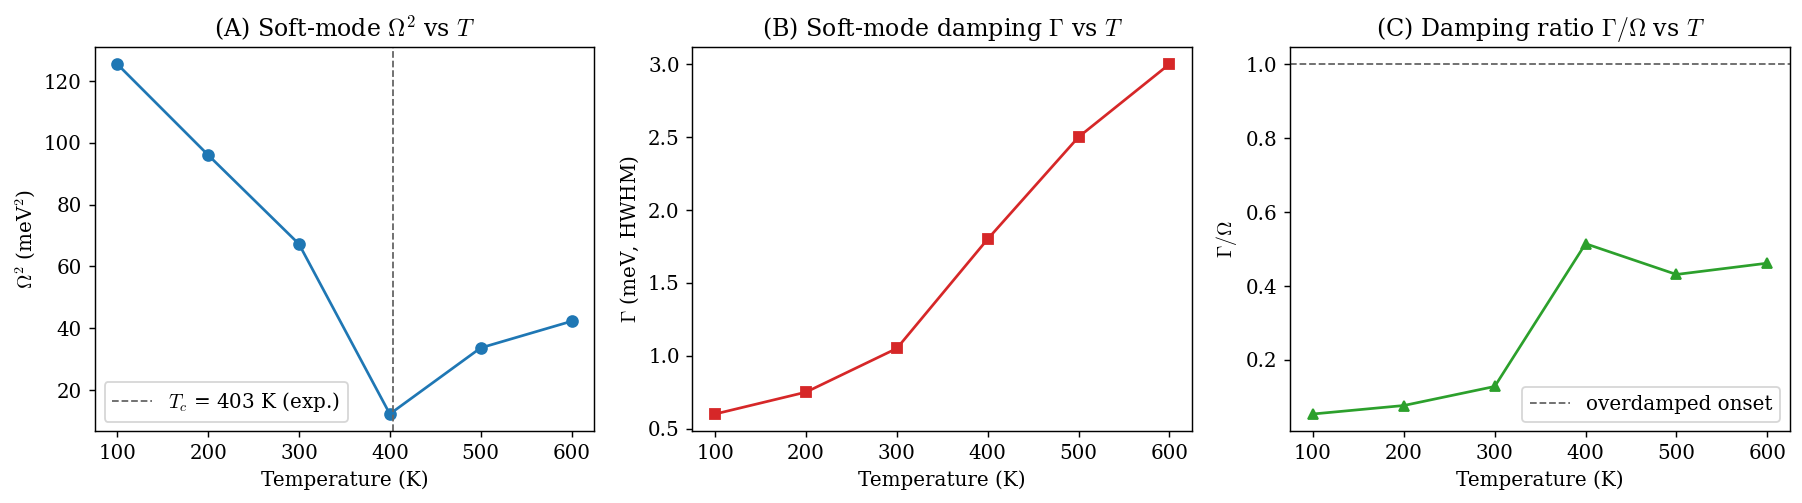

In [3]:
T = soft['temperature_K'].to_numpy()
omega = soft['omega_Q_meV'].to_numpy()
gamma = soft['Gamma_Q_HWHM_meV'].to_numpy()

T_C_EXP = 403.0  # experimental BaTiO3 cubic-tetragonal transition (K)

fig, (axA, axB, axC) = plt.subplots(1, 3, figsize=(14, 4))

axA.plot(T, omega**2, 'o-', color='tab:blue')
axA.axvline(T_C_EXP, ls='--', color='0.4', lw=1.0,
            label=f'$T_c$ = {T_C_EXP:.0f} K (exp.)')
axA.set_xlabel('Temperature (K)')
axA.set_ylabel(r'$\Omega^2$ (meV$^2$)')
axA.set_title(r'(A) Soft-mode $\Omega^2$ vs $T$')
axA.legend()

axB.plot(T, gamma, 's-', color='tab:red')
axB.set_xlabel('Temperature (K)')
axB.set_ylabel(r'$\Gamma$ (meV, HWHM)')
axB.set_title(r'(B) Soft-mode damping $\Gamma$ vs $T$')

axC.plot(T, gamma / omega, '^-', color='tab:green')
axC.axhline(1.0, ls='--', color='0.4', lw=1.0, label='overdamped onset')
axC.set_xlabel('Temperature (K)')
axC.set_ylabel(r'$\Gamma / \Omega$')
axC.set_title(r'(C) Damping ratio $\Gamma/\Omega$ vs $T$')
axC.legend()

fig.tight_layout()
out = FIG_DIR / '01_BTO_soft_mode_inventory.pdf'
fig.savefig(out)
print('saved:', out)
plt.show()

## Shirane neutron data (BTO single-domain, 295 K)

The two CSVs are digitized inelastic-neutron energy-loss spectra of
single-domain **BaTiO$_3$** at 22 C (~295 K, a single temperature), taken
in two different $(q, e)$ configurations from Fig. 4 of Shirane, Axe,
Harada & Linz, *Phys. Rev. B* **2**, 3651 (1970). The two panels expose the
strong soft-mode anisotropy in BTO. **Correction:** Turn 1 mislabeled these
as SrTiO$_3$; the Shirane 1970 paper is on BaTiO$_3$.

**Diagnostic (this turn):** the digitized files appear *swapped* relative to
the published panels. `ShiraneFig4b.csv` carries the sharp ~9 meV TA peak of
published Fig. 4(A) ($q\parallel[110]$, $e\parallel[1\bar{1}0]$), while
`ShiraneFig4a.csv` carries the broad soft-TO feature plus higher TA of
published Fig. 4(B) ($q\parallel[010]$, $e\parallel[100]$). The legend below
reflects this corrected correspondence; the CSV files were left unrenamed
pending visual confirmation against the PDF.

Fig4a.csv shape: (30, 2)
Fig4b.csv shape: (44, 2)


saved: /Users/syed.a.moid/Documents/WORKSPACES/PHD/TC/ferroelectric-kappa-scph/figures/01_BTO_shirane_inventory_295K.pdf


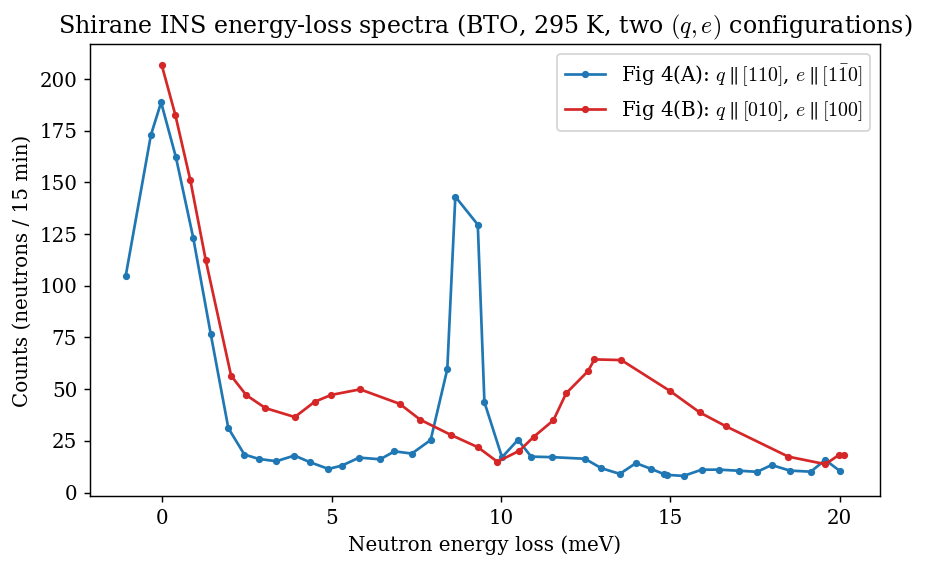

In [4]:
fig4a = load_shirane(DATA_RAW / 'ShiraneFig4a.csv')
fig4b = load_shirane(DATA_RAW / 'ShiraneFig4b.csv')
print('Fig4a.csv shape:', fig4a.shape)
print('Fig4b.csv shape:', fig4b.shape)

fig, ax = plt.subplots(figsize=(7, 4.5))
# Files are swapped vs. published panels (see markdown above): Fig4b.csv ->
# published 4(A); Fig4a.csv -> published 4(B).
for df, label, color in [
    (fig4b, r'Fig 4(A): $q\parallel[110]$, $e\parallel[1\bar{1}0]$', 'tab:blue'),
    (fig4a, r'Fig 4(B): $q\parallel[010]$, $e\parallel[100]$', 'tab:red'),
]:
    d = df.sort_values('energy_loss_meV')
    ax.plot(d['energy_loss_meV'], d['counts'], 'o-', ms=3,
            color=color, label=label)
ax.set_xlabel('Neutron energy loss (meV)')
ax.set_ylabel('Counts (neutrons / 15 min)')
ax.set_title(r'Shirane INS energy-loss spectra (BTO, 295 K, two $(q, e)$ configurations)')
ax.legend()
fig.tight_layout()
out = FIG_DIR / '01_BTO_shirane_inventory_295K.pdf'
fig.savefig(out)
print('saved:', out)
plt.show()

## IR spectra files (inventory only, parsing in notebook 03)

In [5]:
# Lightweight JSON inventory; full parsing now lives in
# fekappa.io.load_ir_spectra and is exercised in notebook 03.
for name in ['BTO_ir_data.json', 'STO_ir_data.json']:
    path = DATA_RAW / name
    with open(path) as fh:
        d = json.load(fh)
    grid = d['frequency_grid_cm1']
    peaks = d['peaks']
    print('=' * 60)
    print(name)
    print('  material:', d['material'])
    print(f"  frequency grid (cm^-1): {min(grid):.2f} -> {max(grid):.2f} "
          f"({len(grid)} points)")
    print('  number of peaks:', len(peaks))
    print('  peak frequencies (cm^-1):',
          [round(p['frequency_cm1'], 2) for p in peaks])
    print('  spectra temperatures:', list(d['spectra'].keys()))

BTO_ir_data.json
  material: BaTiO₃
  frequency grid (cm^-1): 16.68 -> 667.13 (2000 points)
  number of peaks: 5
  peak frequencies (cm^-1): [60.04, 160.11, 173.45, 193.47, 493.67]
  spectra temperatures: ['T_100K', 'T_200K', 'T_300K', 'T_400K', 'T_500K']
STO_ir_data.json
  material: SrTiO₃
  frequency grid (cm^-1): 16.68 -> 667.13 (2000 points)
  number of peaks: 5
  peak frequencies (cm^-1): [91.06, 167.45, 183.79, 200.81, 518.36]
  spectra temperatures: ['T_100K', 'T_200K', 'T_300K', 'T_400K', 'T_500K']


## Summary and next steps

- **6 BaTiO$_3$ temperatures** are available (100-600 K in 100 K steps),
  each with one `polar_soft` mode plus optical/acoustic modes.
- The soft-mode **V-shape is visible around $T_c \approx 400$ K**: $\Omega^2$
  dips to a minimum near 400 K while the damping $\Gamma$ grows
  monotonically with temperature.
- The **Shirane INS spectra are BaTiO$_3$** at 295 K (corrected from
  Turn 1), probing two $(q, e)$ configurations; the digitized panels appear
  swapped (see above).
- **SrTiO$_3$ soft-mode information** comes from the IR absorption spectra in
  `STO_ir_data.json` (5 temperatures); no Quantum-ESPRESSO phonon data is
  available for SrTiO$_3$.
- The IR JSON files share a 2000-point frequency grid with 5 peaks each;
  parsing is implemented in `fekappa.io.load_ir_spectra` (Turn 2).

**Next:** see `02_BTO_scph_fit` for the two-branch SCPH fit of the
BaTiO$_3$ soft mode and `03_STO_ir_fits` for STO soft-mode extraction from
IR spectra.